# 07 · Comparativa v1 frente a v2

**Objetivo de este cuaderno:** poner en la misma tabla la v1 (GRU desde cero, cuadernos 03-05) y la v2 (TinyBERT, cuaderno 06), explicar **por qué la v1 no se promocionaba** y qué cambio aportó cada pieza del nuevo diseño. No se reentrena. Si faltan `resultados/sentimiento.json` o `resultados/v2_sentimiento.json`, vuelve a 03 y 06.


In [1]:
from pathlib import Path
import os, sys, json, time, gc, copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def _raiz():
    aqui = Path.cwd().resolve()
    for cand in [aqui, *aqui.parents]:
        if (cand / "src" / "destilacion_utils.py").exists() and (cand / "notebooks").is_dir():
            return cand
    raise FileNotFoundError(
        "No encuentro la raiz del proyecto de destilacion "
        "(src/destilacion_utils.py + notebooks/)."
    )

RAIZ = _raiz()
sys.path.insert(0, str(RAIZ / "src"))

from destilacion_utils import (
    preparar_rutas,
    fijar_semilla,
    dispositivo,
    configurar_proxy_y_hf,
    softmax_temperatura,
    perdida_destilacion,
    contar_parametros,
    tamano_archivo_mb,
    guardar_json,
    cargar_json,
    fijar_hilos_cpu,
    medir_latencia_transformador,
    cuantizar_dinamico,
    evaluar_puertas_promocion,
)

try:
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    import matplotlib
    matplotlib.use("Agg")

plt.rcParams.update({
    "figure.figsize": (8, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 12,
    "figure.dpi": 110,
})

RUTAS = preparar_rutas(RAIZ)
SEMILLA = fijar_semilla()
CFG_RED = configurar_proxy_y_hf(RAIZ, verbose=True)
DEVICE = dispositivo()
HILOS = fijar_hilos_cpu(4)
print(f"Raíz:        {RAIZ}")
print(f"Dispositivo: {DEVICE}")
print(f"Semilla:     {SEMILLA}")
print(f"Hilos CPU:   {HILOS}")


Configuración de red y Hugging Face
  HTTP_PROXY definido:  False
  HTTPS_PROXY definido: False
  NO_PROXY definido:    False
  Certificado SSL (SSL_CERT_FILE / REQUESTS_CA_BUNDLE): False
  Token de Hugging Face presente: False (no se muestra el valor)
  HF_HOME: /workspace/destilacion/cache-hf
  Modo offline HF: False
  No hizo falta ajustar variables: ya estaban definidas.
Raíz:        /workspace/destilacion
Dispositivo: cpu
Semilla:     42
Hilos CPU:   {'intra_op': 4, 'interop': 1}


## 1. Cargar artefactos


In [2]:
ruta_v1 = RUTAS["resultados"] / "sentimiento.json"
ruta_v2 = RUTAS["resultados"] / "v2_sentimiento.json"
ruta_probe = RUTAS["resultados"] / "v2_probe.json"
faltan = [str(p) for p in (ruta_v1, ruta_v2) if not p.exists()]
assert not faltan, "Faltan:\n- " + "\n- ".join(faltan) + "\nEjecuta los cuadernos 03 y 06."

v1 = cargar_json(ruta_v1)
v2 = cargar_json(ruta_v2)
probe = cargar_json(ruta_probe) if ruta_probe.exists() else None

acc_p = v2["exactitud_profesor"]
puerta = v2["puerta_calidad"]


def fila(nombre, acc, params, ms_p95=None, notas=""):
    hueco = (acc_p - acc) * 100 if acc is not None else None
    return {
        "variante": nombre,
        "exactitud": None if acc is None else round(acc, 4),
        "hueco_vs_profesor_puntos": None if hueco is None else round(hueco, 2),
        "parametros": params,
        "p95_lote_ms": None if ms_p95 is None else round(ms_p95, 2),
        "calidad_ok": None if hueco is None else hueco <= 4.0 + 1e-9,
        "notas": notas,
    }


filas = [
    fila("Profesor DistilBERT (SST-2)", acc_p, v2["modelos"]["profesor"]["parametros"],
         v2["modelos"]["profesor"]["latencia_ms_lote_p95"], "referencia; no se promociona a sí mismo"),
    fila("v1 GRU duro (3 000 frases)", v1["modelos"]["estudiante_duro"]["exactitud"],
         v1["modelos"]["estudiante_duro"]["parametros"],
         v1["modelos"]["estudiante_duro"].get("latencia_ms_lote_p95"),
         "v1: red desde cero, etiquetas duras"),
    fila("v1 GRU destilado (3 000 frases)", v1["modelos"]["estudiante_destilado"]["exactitud"],
         v1["modelos"]["estudiante_destilado"]["parametros"],
         v1["modelos"]["estudiante_destilado"].get("latencia_ms_lote_p95"),
         "v1: misma red, etiquetas blandas; no llega a la puerta de calidad"),
]
# Camino intermedio: BERT pequeño MLM (no TinyBERT), medido en las sondas previas.
if probe:
    for clave, etiqueta in [
        ("hard-16k-2ep", "Sonda: BERT L-4 H-256 duro, 16 000, 2 épocas"),
        ("kd-16k-2ep", "Sonda: BERT L-4 H-256 destilado, 16 000, 2 épocas"),
    ]:
        if clave in probe:
            filas.append(fila(etiqueta, probe[clave]["best_test"], 11_171_074, None,
                              "mismo régimen de datos casi, pero el punto de partida no es TinyBERT"))

filas.append(fila(
    "v2 TinyBERT duro (20 000 frases)",
    v2["modelos"]["estudiante_duro"]["exactitud"],
    v2["modelos"]["estudiante_duro"]["parametros"],
    v2["modelos"]["estudiante_duro"]["latencia_ms_lote_p95"],
    "v2: transformer pequeño ya preentrenado, etiquetas duras",
))
filas.append(fila(
    "v2 TinyBERT destilado fp32",
    v2["modelos"]["estudiante_destilado"]["exactitud"],
    v2["modelos"]["estudiante_destilado"]["parametros"],
    v2["modelos"]["estudiante_destilado"]["latencia_ms_lote_p95"],
    "v2: mismas iniciales, T=3, alpha=0.5",
))
oficial_clave = v2.get("variante_oficial", "estudiante_duro")
precision_oficial = v2.get("precision_oficial", "fp32")
oficial = v2["puertas"].get("oficial") or v2["puertas"].get("fp32_lote16") or v2["puertas"]["oficial_int8_lote16"]

def _es_oficial(clave, prec):
    return clave == oficial_clave and prec == precision_oficial

filas.append(fila(
    "v2 TinyBERT destilado int8",
    v2["modelos"]["estudiante_destilado"]["exactitud_int8"],
    v2["modelos"]["estudiante_destilado"]["parametros"],
    v2["modelos"]["estudiante_destilado"]["latencia_int8_b16"]["ms_lote_p95"],
    "cuantización dinámica: en esta CPU baja la exactitud y no entra en la puerta de calidad",
))
filas.append(fila(
    "v2 TinyBERT duro int8",
    v2["modelos"]["estudiante_duro"]["exactitud_int8"],
    v2["modelos"]["estudiante_duro"]["parametros"],
    v2["modelos"]["estudiante_duro"]["latencia_int8_b16"]["ms_lote_p95"],
    "misma caída de calidad al cuantizar; no se promociona",
))
# Fila oficial (fp32 o int8 según lo medido)
m_of = v2["modelos"][oficial_clave]
if precision_oficial == "int8":
    acc_of, p95_of = m_of["exactitud_int8"], m_of["latencia_int8_b16"]["ms_lote_p95"]
else:
    acc_of, p95_of = m_of["exactitud"], m_of["latencia_ms_lote_p95"]
rol = "duro" if oficial_clave == "estudiante_duro" else "destilado"
filas.append(fila(
    f"v2 TinyBERT {rol} {precision_oficial} (oficial)",
    acc_of,
    m_of["parametros"],
    p95_of,
    "mayor exactitud entre las variantes que cumplen las dos puertas",
))

ablacion = pd.DataFrame(filas)
display(ablacion)

print("Puertas oficiales v2:", f"{oficial_clave} {precision_oficial}, lote 16")
print(oficial["decision"],
      f"hueco={oficial['hueco_puntos']:.2f} puntos  aceleración={oficial['aceleracion_p95']:.2f}×")
if v2.get("nota_oficial"):
    print(v2["nota_oficial"])
if Path(RUTAS["resultados"] / "ejercicio5_promocion.json").exists():
    e5 = cargar_json(RUTAS["resultados"] / "ejercicio5_promocion.json")
    print("Ejercicio 5 sobre la v1:", e5["decision"],
          f"hueco={e5['hueco_puntos']:.2f} puntos  aceleración≈{e5['aceleracion_p95']:.1f}× (ojo: lotes distintos en la v1)")


,variante,exactitud,hueco_vs_profesor_puntos,parametros,p95_lote_ms,calidad_ok,notas
0,Profesor DistilBERT (SST-2),0.9106,0.00,66955010,127.35,True,referencia; no se promociona a sí mismo
1,v1 GRU duro (3 000 frases),0.6502,26.03,2003586,2.77,False,"v1: red desde cero, etiquetas duras"
2,v1 GRU destilado (3 000 frases),0.6743,23.62,2003586,2.80,False,"v1: misma red, etiquetas blandas; no llega a l..."
3,"Sonda: BERT L-4 H-256 duro, 16 000, 2 épocas",0.8073,10.32,11171074,NaN,False,"mismo régimen de datos casi, pero el punto de ..."
4,"Sonda: BERT L-4 H-256 destilado, 16 000, 2 épocas",0.8050,10.55,11171074,NaN,False,"mismo régimen de datos casi, pero el punto de ..."
5,v2 TinyBERT duro (20 000 frases),0.8842,2.64,14350874,16.55,True,"v2: transformer pequeño ya preentrenado, etiqu..."
6,v2 TinyBERT destilado fp32,0.8830,2.75,14350874,16.60,True,"v2: mismas iniciales, T=3, alpha=0.5"
7,v2 TinyBERT destilado int8,0.8589,5.16,14350874,15.22,False,cuantización dinámica: en esta CPU baja la exa...
8,v2 TinyBERT duro int8,0.8589,5.16,14350874,15.21,False,misma caída de calidad al cuantizar; no se pro...
9,v2 TinyBERT duro fp32 (oficial),0.8842,2.64,14350874,16.55,True,mayor exactitud entre las variantes que cumple...


Puertas oficiales v2: estudiante_duro fp32, lote 16
PROMOCIONAR hueco=2.64 puntos  aceleración=7.69×
La variante oficial es TinyBERT duro fp32, lote 16, 4 hilos. int8 baja la exactitud de 88.42% a 85.89% (hueco 5.16 > 4) y apenas recorta latencia (8.37× vs 7.69×). El destilado fp32 también cumpliría (88.30%, hueco 2.75).
Ejercicio 5 sobre la v1: NO PROMOCIONAR hueco=23.62 puntos  aceleración≈166.6× (ojo: lotes distintos en la v1)


## 2. Cómo leer la ablación

Tres mensajes, en este orden:

1. **La destilación de la v1 sí aportó algo, pero no suficiente.** El GRU destilado mejora al GRU duro (en la ejecución de referencia, del 65,0 % al 67,4 %). El hueco con el profesor sigue siendo de más de 20 puntos. Las blandas no inventan capacidad ni un buen punto de partida.
2. **Más datos y un BERT pequeño «genérico» acercan, y aún no bastan.** La sonda con `google/bert_uncased_L-4_H-256_A-4` y 16 000 frases quedó en torno al 80-81 %: claramente por encima del GRU, claramente por debajo de la puerta (87,06 %). Un transformer pequeño entrenado como modelo de lenguaje enmascarado no es lo mismo que un TinyBERT ya destilado de un BERT grande.
3. **El cambio que abre la puerta es el punto de partida (TinyBERT) más datos suficientes.** Con 20 000 frases, el TinyBERT duro en fp32 ya cumple calidad y latencia (lote 16). La destilación de salidas, en este estudiante, **no gana** al duro: TinyBERT ya fue destilado de un BERT grande. La cuantización int8 se midió y aquí **no se promociona**: baja la exactitud por debajo de la puerta y apenas recorta el p95.

En otras palabras: la v1 fallía por **calidad**, no por latencia. El GRU era rapidísimo. La v2 tenía que recuperar calidad sin volver a un modelo del tamaño del profesor.


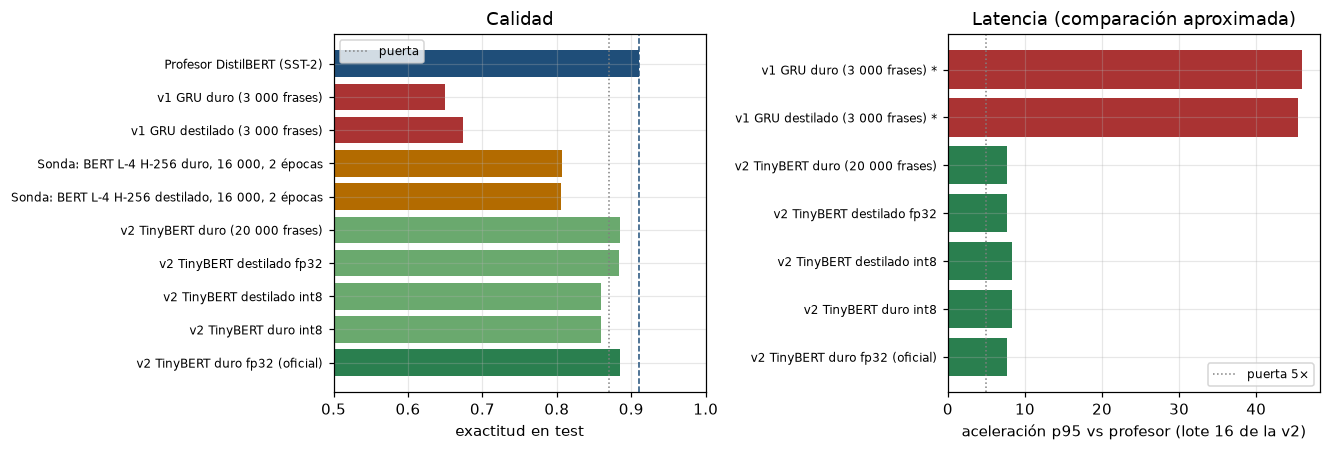

* Las barras de la v1 usan un p95 medido con lote 32: sirven de orden de magnitud, no de medida oficial.


In [3]:
fig, ejes = plt.subplots(1, 2, figsize=(12.2, 4.2))

nombres = ablacion["variante"].tolist()
accs = ablacion["exactitud"].tolist()
colores = ["#1f4e79" if "Profesor" in n else ("#2a7f4f" if "v2" in n and "oficial" in n else ("#6aa96e" if "v2" in n else ("#b36b00" if "Sonda" in n else "#a33"))) for n in nombres]
# exactitud
ypos = np.arange(len(nombres))
ejes[0].barh(ypos, [0 if pd.isna(a) else a for a in accs], color=colores)
ejes[0].set_yticks(ypos, nombres, fontsize=8)
ejes[0].axvline(acc_p, color="#1f4e79", linestyle="--", linewidth=1)
ejes[0].axvline(puerta, color="gray", linestyle=":", linewidth=1, label="puerta")
ejes[0].set_xlim(0.5, 1.0)
ejes[0].set_xlabel("exactitud en test")
ejes[0].set_title("Calidad")
ejes[0].invert_yaxis()
ejes[0].legend(fontsize=8)

# aceleración p95 lote 16, cuando hay cifra del profesor v2
p95_prof = v2["modelos"]["profesor"]["latencia_ms_lote_p95"]
acel = []
etqs = []
for _, r in ablacion.iterrows():
    if r["p95_lote_ms"] and r["p95_lote_ms"] > 0 and "Profesor" not in r["variante"]:
        # Cuidado: el p95 de la v1 se midió con lote 32, no es estrictamente comparable.
        etqs.append(r["variante"] + (" *" if "v1" in r["variante"] else ""))
        acel.append(p95_prof / r["p95_lote_ms"])
ejes[1].barh(np.arange(len(etqs)), acel, color=["#a33" if "v1" in e else "#2a7f4f" for e in etqs])
ejes[1].set_yticks(np.arange(len(etqs)), etqs, fontsize=8)
ejes[1].axvline(5, color="gray", linestyle=":", linewidth=1, label="puerta 5×")
ejes[1].set_xlabel("aceleración p95 vs profesor (lote 16 de la v2)")
ejes[1].set_title("Latencia (comparación aproximada)")
ejes[1].invert_yaxis()
ejes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(RUTAS["resultados"] / "fig_v2_ablacion.png", bbox_inches="tight")
plt.show()
print("* Las barras de la v1 usan un p95 medido con lote 32: sirven de orden de magnitud, no de medida oficial.")


## 3. Las dos decisiones, lado a lado


In [4]:
v1_dec = cargar_json(RUTAS["resultados"] / "ejercicio5_promocion.json") if (RUTAS["resultados"] / "ejercicio5_promocion.json").exists() else None
filas_dec = []
if v1_dec:
    filas_dec.append({
        "serie": "v1 (ejercicio 5)",
        "hueco_puntos": round(v1_dec["hueco_puntos"], 2),
        "aceleracion_p95": round(v1_dec["aceleracion_p95"], 2),
        "cumple_calidad": v1_dec["cumple_calidad"],
        "cumple_latencia": v1_dec["cumple_latencia"],
        "decision": v1_dec["decision"],
        "protocolo": "p95/lote con lotes distintos (16 vs 32); no es el protocolo de la v2",
    })
filas_dec.append({
    "serie": f"v2 oficial ({oficial_clave}, {precision_oficial}, lote 16)",
    "hueco_puntos": round(oficial["hueco_puntos"], 2),
    "aceleracion_p95": round(oficial["aceleracion_p95"], 2),
    "cumple_calidad": oficial["cumple_calidad"],
    "cumple_latencia": oficial["cumple_latencia"],
    "decision": oficial["decision"],
    "protocolo": f"mismo lote 16, 4 hilos, p95 del lote profesor fp32 vs {oficial_clave} {precision_oficial}",
})
for clave, etiqueta in [
    ("fp32_lote16", "v2 fp32, lote 16"),
    ("int8_lote1", "v2 int8, lote 1"),
]:
    d = v2["puertas"][clave]
    filas_dec.append({
        "serie": etiqueta,
        "hueco_puntos": round(d["hueco_puntos"], 2),
        "aceleracion_p95": round(d["aceleracion_p95"], 2),
        "cumple_calidad": d["cumple_calidad"],
        "cumple_latencia": d["cumple_latencia"],
        "decision": d["decision"],
        "protocolo": "mismo protocolo de la v2, otra variante",
    })
display(pd.DataFrame(filas_dec))

guardar_json(
    {"ablacion": ablacion.to_dict(orient="records"), "decisiones": filas_dec, "oficial": oficial},
    RUTAS["resultados"] / "v2_comparativa.json",
)
print("Escrito resultados/v2_comparativa.json")


,serie,hueco_puntos,aceleracion_p95,cumple_calidad,cumple_latencia,decision,protocolo
0,v1 (ejercicio 5),23.62,166.63,False,True,NO PROMOCIONAR,p95/lote con lotes distintos (16 vs 32); no es...
1,"v2 oficial (estudiante_duro, fp32, lote 16)",2.64,7.69,True,True,PROMOCIONAR,"mismo lote 16, 4 hilos, p95 del lote profesor ..."
2,"v2 fp32, lote 16",2.64,7.69,True,True,PROMOCIONAR,"mismo protocolo de la v2, otra variante"
3,"v2 int8, lote 1",5.16,3.87,False,False,NO PROMOCIONAR,"mismo protocolo de la v2, otra variante"


Escrito resultados/v2_comparativa.json


## 4. Conclusiones para un servicio

- **Promociona el par**, no un fichero suelto: profesor (id y revisión), estudiante, tokenizador, \(T\), \(\alpha\), semilla, recuento de datos, protocolo de latencia (hilos, lote) y si va cuantizado o en ONNX.
- **Mide la latencia en el entorno de despliegue**, con el lote real. Las cifras de este cuaderno son de una CPU concreta y 4 hilos. Un lote 1 es más exigente que un lote 16; en esta máquina el lote 1 no llega a 5×. La cuantización int8 hay que **remeedir en exactitud**: aquí no entró en la puerta de calidad.
- **No destiles un estudiante inadecuado esperando un milagro.** Si el punto de partida es un GRU aleatorio o un BERT diminuto poco preparado, las blandas ayudan poco. Cambia la arquitectura o el preentrenamiento antes de alargar las épocas.
- **La cuantización y ONNX son recortes de coste, no de tarea.** Van después de tener calidad. ONNX Runtime es el camino habitual a un servicio; `quantize_dynamic` es el recorte que cabe en este cuaderno, en puro PyTorch, en CPU.
- Las puertas del ejercicio 5 siguen siendo las mismas. La v1 las suspendía. La v2, en esta ejecución, las cumple con el TinyBERT duro en fp32 (lote 16). La variante concreta queda en `resultados/v2_sentimiento.json`.
